# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : M. Zacky Mahendra
- NIM   : 241011402133
- Kelas : Reg B


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [18]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 33  # dua digit terakhir NIM: 241011402133


In [19]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    indices = np.arange(len(X))
    rng = np.random.RandomState(random_state)
    rng.shuffle(indices)
    n_test = int(np.ceil(len(X) * test_size))
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40, 1)


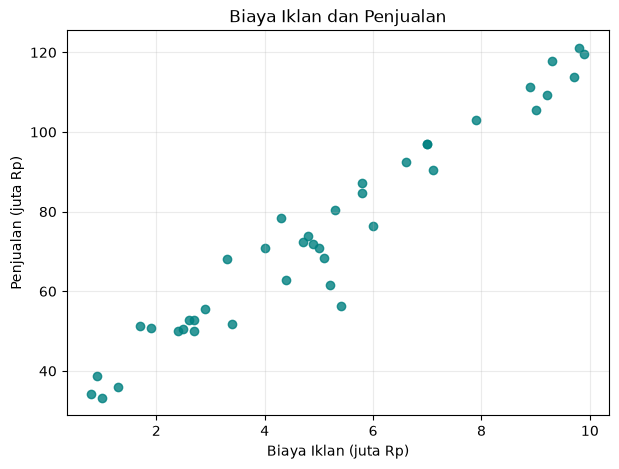

In [20]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print(f"Jumlah baris: {len(df_ads)}")
X_ads = df_ads[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = df_ads["Penjualan"].to_numpy(dtype=float).reshape(-1, 1)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_ads[:, 0], y_ads[:, 0], color="teal", alpha=0.8)
plt.title("Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [21]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train_ads.shape)
print("X_test :", X_test_ads.shape)
print("y_train:", y_train_ads.shape)
print("y_test :", y_test_ads.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32, 1)
y_test : (8, 1)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [22]:
# Jawaban A3
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        params = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
        self.intercept_ = float(params[0, 0])
        self.coef_ = params[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return (self.intercept_ + X @ self.coef_).reshape(-1, 1)

linear_model = LinearRegression().fit(X_train_ads, y_train_ads)
print(f"Intercept (b): {linear_model.intercept_:.4f}")
print(f"Koefisien (m): {linear_model.coef_[0]:.4f}")
print(f"Persamaan: y_hat = {linear_model.intercept_:.4f} + {linear_model.coef_[0]:.4f}X")


Intercept (b): 27.5244
Koefisien (m): 9.0937
Persamaan: y_hat = 27.5244 + 9.0937X


**Jawaban A3 (interpretasi):** Koefisien biaya iklan sebesar 9.0937 berarti, menurut model, kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan penjualan sekitar Rp9.09 juta. Ini adalah hubungan linear yang diperkirakan dari data, bukan bukti bahwa iklan sendiri menyebabkan seluruh kenaikan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [23]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    total = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum(errors ** 2) / total if total else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

train_metrics_ads = regression_metrics(y_train_ads, linear_model.predict(X_train_ads))
test_metrics_ads = regression_metrics(y_test_ads, linear_model.predict(X_test_ads))
regression_results = pd.DataFrame(
    [train_metrics_ads, test_metrics_ads], index=["Training", "Testing"]
)
display(regression_results.round(4))


,MAE,MSE,RMSE,R2
Training,4.4379,36.0328,6.0027,0.9451
Testing,5.3968,39.0602,6.2498,0.9285


**Jawaban A4 (analisis):** Pada data testing, RMSE sebesar 6.2498 juta Rp berarti kesalahan prediksi tipikal model sekitar Rp6.25 juta dalam satuan penjualan. Nilai $R^2=0.9285$ menunjukkan model menjelaskan sekitar 92.85% variasi penjualan pada data testing. Hasil training ($R^2=0.9451$, RMSE 6.0027) dan testing cukup berdekatan, sehingga model tampak baik pada dataset ini; namun ukuran data testing hanya 8 bulan, jadi evaluasi masih terbatas.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/Users/zackymahendra/.venvs/uts-machine-learning/lib/python3.15/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


,Learning rate,Intercept,Koefisien,Status,Loss akhir
0,0.001,1.885531e+01,1.041569e+01,konvergen,52.65826
1,0.020,2.752435e+01,9.093740e+00,konvergen,36.03279
2,0.100,-8.975414e+151,-5.885878e+152,divergen,inf


Normal equation: b=27.52435, m=9.09374


/Users/zackymahendra/.venvs/uts-machine-learning/lib/python3.15/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


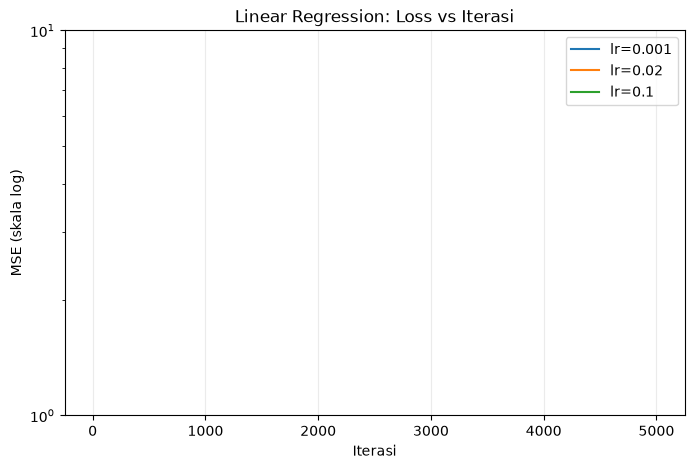

In [24]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        self.theta_ = np.zeros((X_bias.shape[1], 1))
        self.loss_history_ = []
        self.diverged_ = False
        for _ in range(self.n_iterations):
            error = X_bias @ self.theta_ - y
            loss = float(np.mean(error ** 2))
            if not np.isfinite(loss):
                self.diverged_ = True
                self.loss_history_.append(np.inf)
                break
            self.loss_history_.append(loss)
            gradient = X_bias.T @ error / len(X_bias)
            self.theta_ -= self.learning_rate * gradient
        self.intercept_ = float(self.theta_[0, 0])
        self.coef_ = self.theta_[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return (self.intercept_ + X @ self.coef_).reshape(-1, 1)

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_summary = []
for rate in learning_rates:
    gd_model = LinearRegressionGD(learning_rate=rate, n_iterations=5000).fit(
        X_train_ads, y_train_ads
    )
    gd_models[rate] = gd_model
    gd_summary.append({
        "Learning rate": rate,
        "Intercept": gd_model.intercept_,
        "Koefisien": gd_model.coef_[0],
        "Status": "divergen" if gd_model.diverged_ else "konvergen",
        "Loss akhir": gd_model.loss_history_[-1],
    })
display(pd.DataFrame(gd_summary).round(5))
print(f"Normal equation: b={linear_model.intercept_:.5f}, m={linear_model.coef_[0]:.5f}")

plt.figure(figsize=(8, 5))
for rate, gd_model in gd_models.items():
    losses = np.asarray(gd_model.loss_history_)
    plt.plot(np.arange(1, len(losses) + 1), losses, label=f"lr={rate}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.title("Linear Regression: Loss vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Jawaban A5 (analisis):** Learning rate `0.001` masih terlalu lambat: setelah 5.000 iterasi loss-nya 52.6583 dan parameternya belum mendekati normal equation. Learning rate `0.02` konvergen dengan loss 36.0328 dan parameter hampir sama dengan normal equation ($b=27.5244$, $m=9.0937$). Learning rate `0.1` terlalu besar dan divergen; parameter membesar hingga sekitar $10^{152}$ lalu loss menjadi tak hingga. Peringatan overflow menunjukkan angka melampaui rentang representasi float, sehingga gradien tidak lagi memberi pembaruan yang bermakna.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

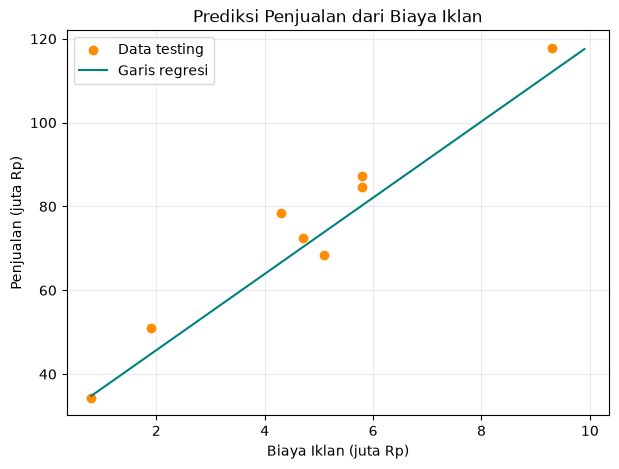

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,68.446
1,7.0,91.181
2,12.0,136.649


In [25]:
# Jawaban A6
X_line = np.linspace(X_ads.min(), X_ads.max(), 200).reshape(-1, 1)
y_line = linear_model.predict(X_line)
plt.figure(figsize=(7, 5))
plt.scatter(X_test_ads[:, 0], y_test_ads[:, 0], color="darkorange", label="Data testing")
plt.plot(X_line[:, 0], y_line[:, 0], color="teal", label="Garis regresi")
plt.title("Prediksi Penjualan dari Biaya Iklan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

new_ad_costs = np.array([[4.5], [7.0], [12.0]])
new_sales_predictions = linear_model.predict(new_ad_costs).reshape(-1)
prediction_table = pd.DataFrame({
    "BiayaIklan (juta Rp)": new_ad_costs.reshape(-1),
    "PrediksiPenjualan (juta Rp)": new_sales_predictions,
})
display(prediction_table.round(3))


**Jawaban A6 (analisis):** Model memprediksi penjualan sekitar Rp68.446 juta untuk biaya iklan Rp4.5 juta, Rp91.181 juta untuk Rp7 juta, dan Rp136.649 juta untuk Rp12 juta. Data iklan dalam dataset hanya berkisar Rp0.8–9.9 juta, sehingga prediksi Rp12 juta merupakan ekstrapolasi. Hasil itu kurang dapat dipercaya karena pola hubungan linear di atas rentang pengamatan belum teruji dan faktor lain yang memengaruhi penjualan tidak dimodelkan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64
Shape X: (60, 2) | Shape y: (60, 1)


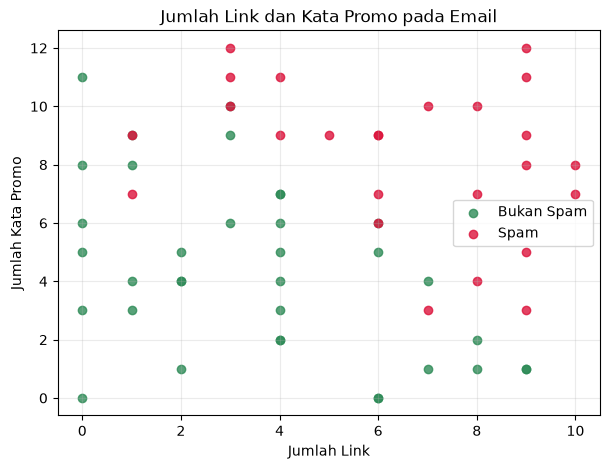

In [26]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())
print("Jumlah kelas:")
print(df_email["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam", 1: "Spam"}))
X_email = df_email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = df_email["Spam"].to_numpy(dtype=int).reshape(-1, 1)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
for label, color, name in [(0, "seagreen", "Bukan Spam"), (1, "crimson", "Spam")]:
    mask = y_email[:, 0] == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], color=color, label=name, alpha=0.8)
plt.title("Jumlah Link dan Kata Promo pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -9.00858
Koefisien (m1, m2): 0.78914, 0.77980
P(Spam) = sigmoid(-9.00858 + 0.78914*JumlahLink + 0.77980*KataPromo)


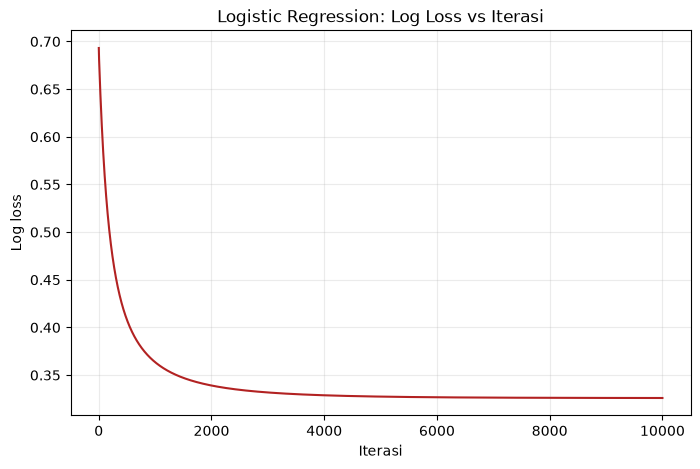

In [27]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        return self.sigmoid(X_bias @ self.theta_)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        self.theta_ = np.zeros((X_bias.shape[1], 1))
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            probabilities = self.sigmoid(X_bias @ self.theta_)
            probabilities_safe = np.clip(probabilities, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(probabilities_safe) + (1 - y) * np.log(1 - probabilities_safe))
            self.loss_history_.append(float(loss))
            gradient = X_bias.T @ (probabilities - y) / len(X_bias)
            self.theta_ -= self.learning_rate * gradient
        self.intercept_ = float(self.theta_[0, 0])
        self.coef_ = self.theta_[1:, 0]
        return self

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

logistic_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(
    X_train_email, y_train_email
)
print(f"Intercept (b): {logistic_model.intercept_:.5f}")
print(f"Koefisien (m1, m2): {logistic_model.coef_[0]:.5f}, {logistic_model.coef_[1]:.5f}")
print(
    "P(Spam) = sigmoid({:.5f} + {:.5f}*JumlahLink + {:.5f}*KataPromo)".format(
        logistic_model.intercept_, logistic_model.coef_[0], logistic_model.coef_[1]
    )
)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(logistic_model.loss_history_) + 1), logistic_model.loss_history_, color="firebrick")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Log Loss vs Iterasi")
plt.grid(alpha=0.25)
plt.show()


**Jawaban B2 (analisis):** Grafik log loss turun selama proses training dan mendekati nilai yang stabil, menandakan pembaruan gradient descent mulai konvergen pada data training. Model menghasilkan $b=-9.0086$, $m_1=0.7891$, dan $m_2=0.7798$; kedua fitur menaikkan skor spam ketika nilainya meningkat, dengan asumsi fitur lain tetap.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [28]:
# Jawaban B3
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=int).reshape(-1)
    matrix = np.zeros((2, 2), dtype=int)
    for actual, predicted in zip(y_true, y_pred):
        matrix[actual, predicted] += 1
    return matrix

def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return float(np.mean(y_true == y_pred))

def classification_metrics(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = matrix.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": precision, "Recall": recall, "F1": f1,
    }

y_test_pred = logistic_model.predict(X_test_email)
test_classification_metrics = classification_metrics(y_test_email, y_test_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test_email, y_test_pred))
display(pd.DataFrame([test_classification_metrics], index=["Testing"]).round(4))


Confusion matrix [[TN, FP], [FN, TP]]:
[[7 1]
 [0 7]]


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1
Testing,0.9333,7,1,0,7,0.875,1.0,0.9333


**Jawaban B3 (analisis):** Pada data testing, confusion matrix `[[7, 1], [0, 7]]` memberi akurasi 0.9333, precision 0.875, recall 1.0, dan F1 0.9333. FP berarti email bukan spam keliru ditandai sebagai spam; FN berarti spam lolos ke inbox. FP dapat lebih merugikan karena pesan sah yang penting berisiko tersembunyi, meskipun FN juga mengganggu dan dapat berisiko. Karena itu pemilihan threshold perlu mempertimbangkan konsekuensi penggunaan, bukan akurasi saja.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-9.00858 + (0.78914)*JumlahLink) / (0.77980)


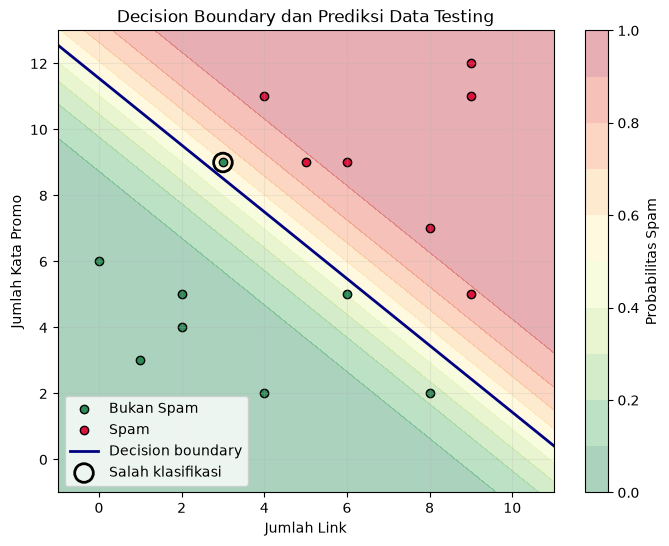

Data testing yang salah diklasifikasikan:


,Index data,JumlahLink,KataPromo,Aktual,Prediksi
0,0,3.0,9.0,0,1


In [29]:
# Jawaban B4
m1, m2 = logistic_model.coef_
b = logistic_model.intercept_
print(f"Decision boundary: KataPromo = -({b:.5f} + ({m1:.5f})*JumlahLink) / ({m2:.5f})")

x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
probability_grid = logistic_model.predict_proba(grid).reshape(xx.shape)
wrong = y_test_pred.reshape(-1) != y_test_email.reshape(-1)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probability_grid, levels=np.linspace(0, 1, 11), cmap="RdYlGn_r", alpha=0.35)
plt.colorbar(label="Probabilitas Spam")
for label, color, name in [(0, "seagreen", "Bukan Spam"), (1, "crimson", "Spam")]:
    mask = y_test_email[:, 0] == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], color=color, edgecolor="black", label=name)
if abs(m2) > 1e-12:
    boundary_x = np.linspace(x_min, x_max, 250)
    boundary_y = -(b + m1 * boundary_x) / m2
    plt.plot(boundary_x, boundary_y, color="navy", linewidth=2, label="Decision boundary")
plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], s=180, facecolors="none", edgecolors="black", linewidths=2, label="Salah klasifikasi")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary dan Prediksi Data Testing")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

misclassified_email = pd.DataFrame({
    "Index data": np.flatnonzero(wrong),
    "JumlahLink": X_test_email[wrong, 0],
    "KataPromo": X_test_email[wrong, 1],
    "Aktual": y_test_email[wrong, 0],
    "Prediksi": y_test_pred[wrong, 0],
})
print("Data testing yang salah diklasifikasikan:")
display(misclassified_email)


**Jawaban B4 (analisis):** Garis keputusan diperoleh dari $x_2=-(-9.0086+0.7891x_1)/0.7798$. Pada data testing, satu email salah klasifikasi: email dengan 3 link dan 9 kata promo sebenarnya Bukan Spam, tetapi diprediksi Spam. Titik tersebut ditandai dengan lingkaran hitam pada grafik.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [30]:
# Jawaban B5
threshold_results = []
for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = (logistic_model.predict_proba(X_test_email) >= threshold).astype(int)
    metrics = classification_metrics(y_test_email, threshold_pred)
    threshold_results.append({
        "Threshold": threshold,
        "TN": metrics["TN"], "FP": metrics["FP"],
        "FN": metrics["FN"], "TP": metrics["TP"],
        "Precision": metrics["Precision"], "Recall": metrics["Recall"],
    })
threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(4))

# Pilih threshold tinggi untuk mengurangi risiko email sah masuk folder spam.
CHOSEN_THRESHOLD = 0.7
print(f"Threshold pilihan untuk prediksi lanjutan: {CHOSEN_THRESHOLD}")


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,6,2,0,7,0.7778,1.0
1,0.5,7,1,0,7,0.8750,1.0
2,0.7,8,0,0,7,1.0000,1.0


Threshold pilihan untuk prediksi lanjutan: 0.7


**Jawaban B5 (analisis):** Menurunkan threshold dari 0.5 ke 0.3 menaikkan recall tetap 1.0 tetapi menurunkan precision dari 0.875 menjadi 0.7778 karena FP bertambah dari 1 menjadi 2. Menaikkan threshold ke 0.7 meningkatkan precision menjadi 1.0 dan pada sampel testing ini recall tetap 1.0, dengan confusion matrix `[[8, 0], [0, 7]]`. Saya memilih threshold 0.7 untuk mengurangi risiko email sah masuk folder spam; hasil sempurna tersebut perlu diuji lagi pada data yang lebih banyak karena set testing hanya 15 email.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [31]:
# Jawaban B6
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11],
})
new_email_X = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_email_probabilities = logistic_model.predict_proba(new_email_X).reshape(-1)
new_emails["Probabilitas Spam"] = new_email_probabilities
new_emails["Prediksi"] = np.where(
    new_email_probabilities >= CHOSEN_THRESHOLD, "Spam", "Bukan Spam"
)
new_emails["Threshold"] = CHOSEN_THRESHOLD
display(new_emails.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0013,Bukan Spam,0.7
1,E2,5,6,0.4051,Bukan Spam,0.7
2,E3,9,10,0.9972,Spam,0.7
3,E4,2,11,0.7590,Spam,0.7


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression digunakan untuk klasifikasi karena keluaran akhirnya berupa kelas, misalnya Spam atau Bukan Spam. Model menghitung skor linear dari fitur, lalu sigmoid mengubah skor itu menjadi probabilitas antara 0 dan 1. Ambang probabilitas digunakan untuk menentukan kelas prediksi.

**Jawaban C2:** Normal equation menghitung parameter secara langsung melalui operasi matriks, sehingga tidak perlu menentukan learning rate atau jumlah iterasi. Gradient descent memperbarui parameter sedikit demi sedikit dengan bergerak mengikuti arah gradien loss. Gradient descent lebih sesuai ketika jumlah fitur sangat besar sehingga operasi matriks langsung mahal, tetapi learning rate perlu dipilih dengan hati-hati.

**Jawaban C3:** Data testing mengukur kemampuan model pada data yang tidak dipakai untuk belajar, sehingga memberikan gambaran generalisasi yang lebih jujur. Nilai training saja bisa tampak bagus karena model sudah melihat data tersebut. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training dan performanya menurun pada data baru.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, dan MSE mengukur rata-rata kuadrat jarak prediksi terhadap nilai sebenarnya. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut memihak kelas yang benar dan memberi penalti besar pada prediksi yang sangat yakin tetapi salah. Karena itu, loss disesuaikan dengan bentuk output model.

**Jawaban C5:** Pembagian training dan testing dapat berbeda karena memakai nilai `random_state` yang berbeda, sehingga parameter dan metrik ikut berubah. Hasil juga bergantung pada inisialisasi, learning rate, jumlah iterasi, threshold, serta detail implementasi model. Pada Logistic Regression, regularisasi dan solver juga dapat mengubah hasil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [32]:
# Jawaban Bonus
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    sklearn_linear = SklearnLinearRegression().fit(X_train_ads, y_train_ads.reshape(-1))
    sklearn_linear_pred = sklearn_linear.predict(X_test_ads)
    sklearn_logistic = SklearnLogisticRegression(
        C=np.inf, l1_ratio=0, solver="lbfgs", max_iter=5000
    ).fit(X_train_email, y_train_email.reshape(-1))
    sklearn_logistic_pred = sklearn_logistic.predict(X_test_email)

    comparison = pd.DataFrame([
        {
            "Model": "Linear Regression (NumPy)",
            "Intercept": linear_model.intercept_,
            "Koefisien": linear_model.coef_[0],
            "Metrik testing": f"R2={test_metrics_ads['R2']:.4f}",
        },
        {
            "Model": "Linear Regression (sklearn)",
            "Intercept": float(sklearn_linear.intercept_),
            "Koefisien": float(sklearn_linear.coef_[0]),
            "Metrik testing": f"R2={regression_metrics(y_test_ads, sklearn_linear_pred)['R2']:.4f}",
        },
        {
            "Model": "Logistic Regression (NumPy)",
            "Intercept": logistic_model.intercept_,
            "Koefisien": np.array2string(logistic_model.coef_, precision=4),
            "Metrik testing": f"Accuracy={test_classification_metrics['Accuracy']:.4f}",
        },
        {
            "Model": "Logistic Regression (sklearn)",
            "Intercept": float(sklearn_logistic.intercept_[0]),
            "Koefisien": np.array2string(sklearn_logistic.coef_[0], precision=4),
            "Metrik testing": f"Accuracy={accuracy_score(y_test_email, sklearn_logistic_pred):.4f}",
        },
    ])
    display(comparison)
except ImportError as error:
    print("Bonus memerlukan scikit-learn:", error)


,Model,Intercept,Koefisien,Metrik testing
0,Linear Regression (NumPy),27.524351,9.093743,R2=0.9285
1,Linear Regression (sklearn),27.524351,9.093743,R2=0.9285
2,Logistic Regression (NumPy),-9.008579,[0.7891 0.7798],Accuracy=0.9333
3,Logistic Regression (sklearn),-9.269651,[0.8133 0.8018],Accuracy=0.9333


**Jawaban Bonus (analisis):** Hasil Linear Regression NumPy dan scikit-learn sama (intercept 27.5244, koefisien 9.0937, dan $R^2$ testing 0.9285), sesuai solusi least squares yang sama. Logistic Regression menghasilkan akurasi testing yang sama, 0.9333, tetapi koefisiennya sedikit berbeda: NumPy $[-9.0086, 0.7891, 0.7798]$ dan scikit-learn sekitar $[-9.2697, 0.8133, 0.8018]$. Perbedaan tersebut terutama berasal dari proses optimisasi dan kriteria berhenti yang berbeda; scikit-learn diatur tanpa regularisasi (`C=np.inf`).